# Figure 3: what the deposited atom names add

Three inputs per model, **single seed (42)**: SMILES, the CCD molecule with generic atom names, and the full CCD code. Left: success rate. Right: how many structures flip when generic names are replaced by deposited names.

Local models (Boltz-2, OF3, OBv0): hits per structure come from `data/names_effect_per_structure.csv`. AlphaFold3: from `data/matrix_poses.csv.gz` (its generic-name arm is `ccd_genericnames`). Rates are on the structures every model ran in all three arms.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))   # run from notebooks/
import common as C
import matplotlib as mpl
from matplotlib.patches import Patch

SEED = 42
MODELS = ["Boltz-2", "OF3", "OBv0", "AlphaFold3"]
LOCAL = MODELS[:3]
ARMS = [("SMILES", C.SMILES), ("CCD + generic atom names", C.GENERIC), ("CCD (deposited names)", C.CCD)]

## Hits per structure and arm

In [2]:
ps = pd.read_csv(C.DATA / "names_effect_per_structure.csv")
ps["model"] = ps.model.replace({"OF3 p2": "OF3"})            # the data file calls it "OF3 p2"
poses = pd.read_csv(C.DATA / "matrix_poses.csv.gz")


def local_hits(model, target):
    """structure -> hit (best-of-5 within 2 A) under smiles / gen / ccd."""
    s = ps[(ps.model == model) & (ps.target == target)]
    chem = s[s.step == "chemistry only"].set_index("structure")                 # smiles -> gen
    names = s[s.step == "names on top of chemistry"].set_index("structure")     # gen -> ccd
    ids = sorted(set(chem.index) & set(names.index))
    assert (chem.loc[ids, "upper_hit"] == names.loc[ids, "lower_hit"]).all(), "generic-name arm disagrees between steps"
    return pd.DataFrame({"smiles": chem.loc[ids, "lower_hit"], "gen": chem.loc[ids, "upper_hit"],
                         "ccd": names.loc[ids, "upper_hit"]}).astype(float)


def af3_hits(target):
    a = poses[(poses.model == "af3") & (poses.status == "ok") & (poses.target == target)
              & (poses.seed == SEED)]
    best = a.groupby(["input", "structure"]).ligand_rmsd.min().unstack("input")
    best = best[["smiles", "ccd_genericnames", "ccd"]].dropna().rename(columns={"ccd_genericnames": "gen"})
    return (best <= 2).astype(float)


rows, shared, names_dir = [], {}, {}
for tgt, key in (("PXR", "pxr"), ("CYP3A4", "cyp3a4")):
    per = {m: local_hits(m, tgt) for m in LOCAL}
    per["AlphaFold3"] = af3_hits(key)
    ids = sorted(set.intersection(*(set(h.index) for h in per.values())))     # structures every model ran in every arm
    shared[tgt] = ids
    for m in MODELS:
        h = per[m].loc[ids]
        rows.append(dict(target=tgt, model=m, n=len(ids), **{a: 100 * h[a].mean() for a in ("smiles", "gen", "ccd")}))
    names_dir[tgt] = pd.DataFrame({m: (per[m].loc[ids].ccd - per[m].loc[ids].gen).astype(int) for m in MODELS})  # +1 improved, -1 worse
rates = pd.DataFrame(rows).set_index(["target", "model"])
print({t: len(v) for t, v in shared.items()}, "structures shared by all four models")
rates.round(1)

{'PXR': 48, 'CYP3A4': 85} structures shared by all four models


n  smiles   gen   ccd
target model                             
PXR    Boltz-2     48    45.8  33.3  60.4
       OF3         48    29.2  27.1  39.6
       OBv0        48    27.1  27.1  37.5
       AlphaFold3  48    43.8  50.0  50.0
CYP3A4 Boltz-2     85    42.4  48.2  62.4
       OF3         85    40.0  45.9  43.5
       OBv0        85    37.6  38.8  44.7
       AlphaFold3  85    47.1  54.1  54.1

## Structures that flip when generic names become deposited names

In [3]:
flips = pd.DataFrame({(t, m): dict(improved=int((d[m] > 0).sum()), worse=int((d[m] < 0).sum()))
                      for t, d in names_dir.items() for m in MODELS}).T
flips

improved  worse
PXR    Boltz-2           14      1
       OF3                8      2
       OBv0               7      2
       AlphaFold3         4      4
CYP3A4 Boltz-2           16      4
       OF3                7      9
       OBv0               6      1
       AlphaFold3         5      5

## Figure

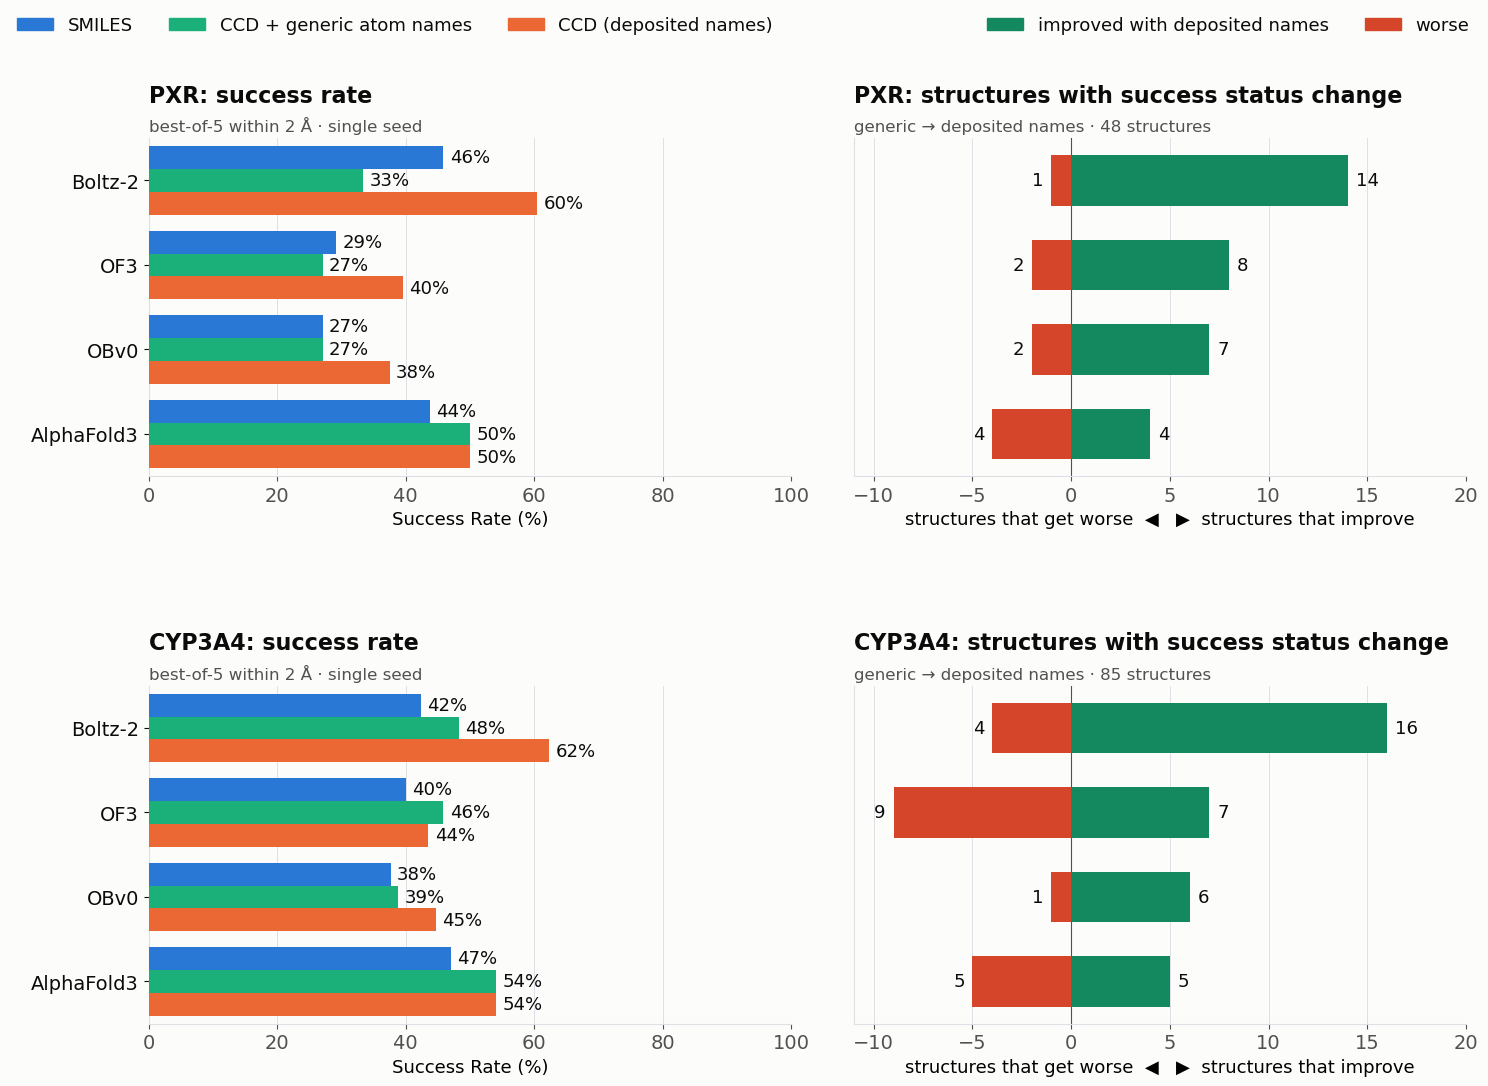

In [4]:
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#dde1e5", "#fcfcfb"
GOOD, BAD = "#14895f", "#d4452a"
mpl.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "font.size": 9,
                     "text.color": INK, "xtick.color": INK_2, "ytick.color": INK, "axes.edgecolor": GRID, "axes.linewidth": 0.8})
FS = dict(tick=14, label=13, title=16, sub=12, value=13, legend=13)

fig = plt.figure(figsize=(17, 11.5))
gs = fig.add_gridspec(2, 2, width_ratios=[1.05, 1], hspace=0.62, wspace=0.1)
y, w = list(range(len(MODELS))), 0.27
for r, tgt in enumerate(("PXR", "CYP3A4")):
    n = int(rates.loc[tgt].n.iloc[0])
    axr = fig.add_subplot(gs[r, 0])
    axb = fig.add_subplot(gs[r, 1], sharey=axr)

    # right: structures that get worse / improve with deposited names
    for i, m in enumerate(MODELS):
        up, dn = int((names_dir[tgt][m] > 0).sum()), int((names_dir[tgt][m] < 0).sum())
        axb.barh(i, -dn, 0.6, color=BAD, zorder=3)
        axb.barh(i, up, 0.6, color=GOOD, zorder=3)
        if dn:
            axb.text(-dn - 0.4, i, f"{dn}", ha="right", va="center", fontsize=FS["value"])
        axb.text(up + 0.4, i, f"{up}", ha="left", va="center", fontsize=FS["value"])
    axb.axvline(0, color=INK_2, lw=0.8)
    axb.set_xlim(-11, 20)
    axr.set_yticks(y, MODELS, fontsize=FS["tick"])
    axr.set_ylim(len(MODELS) - 0.5, -0.5)
    plt.setp(axb.get_yticklabels(), visible=False)
    axb.tick_params(axis="y", length=0)
    axb.tick_params(axis="x", labelsize=FS["tick"])
    axb.xaxis.grid(True, color=GRID, linewidth=0.7, zorder=0)
    axb.set_axisbelow(True)
    axb.set_xlabel("structures that get worse  ◀   ▶  structures that improve", fontsize=FS["label"])
    axb.set_title(f"{tgt}: structures with success status change", loc="left", fontweight="bold", fontsize=FS["title"], pad=26)
    axb.text(0, 1.02, f"generic → deposited names · {n} structures", transform=axb.transAxes, fontsize=FS["sub"], color=INK_2)

    # left: success rate of the three inputs on the same structures
    sub = rates.loc[tgt]
    for k, (lab, col) in enumerate(ARMS):
        vals = [sub.loc[m, ["smiles", "gen", "ccd"][k]] for m in MODELS]
        pos = [i + (k - 1) * w for i in y]
        axr.barh(pos, vals, w, color=col, zorder=3)
        for p_, v in zip(pos, vals):
            axr.text(v + 1, p_, f"{v:.0f}%", va="center", fontsize=FS["value"])
    axr.set_xlim(0, 100)
    axr.tick_params(axis="x", labelsize=FS["tick"])
    axr.xaxis.grid(True, color=GRID, linewidth=0.7, zorder=0)
    axr.set_axisbelow(True)
    axr.set_xlabel("Success Rate (%)", fontsize=FS["label"])
    axr.set_title(f"{tgt}: success rate", loc="left", fontweight="bold", fontsize=FS["title"], pad=26)
    axr.text(0, 1.02, "best-of-5 within 2 Å · single seed", transform=axr.transAxes, fontsize=FS["sub"], color=INK_2)
    for a in (axb, axr):
        for s in ("top", "right"):
            a.spines[s].set_visible(False)

fig.legend(handles=[Patch(color=GOOD, label="improved with deposited names"), Patch(color=BAD, label="worse")],
           loc="upper center", bbox_to_anchor=(0.76, 1.0), ncols=2, frameon=False, fontsize=FS["legend"])
fig.legend(handles=[Patch(color=c, label=l) for l, c in ARMS], loc="upper center", bbox_to_anchor=(0.27, 1.0),
           ncols=3, frameon=False, fontsize=FS["legend"])
fig.savefig(C.FIGS / "fig3_atom_names.png", dpi=300, bbox_inches="tight")
plt.show()